# Prova N1

# Questão 1: Exploração Inicial dos Dados (2 pontos)

a) Descreva brevemente o conjunto de dados CMU Sleep, incluindo a origem e o que os dados representam.

Esse conjunto de dados tem vários registros de estudantes do primeiro ano dessas 3 universidades:
- Carnegie Mellon University (CMU), a STEM-focused private university
- The University of Washington (UW), a large public university
- Notre Dame University (ND), a private Catholic university

Cada estudante recebeu um dispositivo para rastrear os padrões de sono por um mês, essa é a origem dos dados. Eles representam as informações obtidas pelo dispositivo fitbit dado a cada estudante.

b) Realize uma análise exploratória inicial (EDA) e identifique pelo menos três características importantes dos dados (como variáveis, tipos de dados e estatísticas descritivas).

Variáveis: 'study','cohort','demo_race', 'demo_gender', 'demo_firstgen', 'bedtime_mssd', 'TotalSleepTime', 'midpoint_sleep', 'frac_nights_with_data', 'daytime_sleep', 'cum_gpa', 'term_gpa', 'term_units', 'Zterm_units_ZofZ'





In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('/content/drive/MyDrive/ColabNotebooks/Mackenzie/4Semestre/AnaliseDeDados/ProvaN1/cmu-sleep.csv')

In [4]:
print(df.head())

   subject_id  study cohort demo_race demo_gender demo_firstgen  bedtime_mssd  \
0         185      5   lac1         1           1             0      0.116727   
1         158      5   lac1         0           1             0      0.141681   
2         209      5   lac1         1           1             0      1.529289   
3         102      5   lac1         0           1             1      0.130148   
4         174      5   lac1         1           1             0      0.130181   

   TotalSleepTime  midpoint_sleep  frac_nights_with_data  daytime_sleep  \
0      432.200000      458.660000               0.862069      24.160000   
1      391.931035      364.465517               1.000000      13.137931   
2      344.304348      560.891304               0.793103      14.956522   
3      392.620690      416.482759               1.000000      54.551724   
4      423.421053      368.763158               0.655172      10.526316   

   cum_gpa  term_gpa term_units Zterm_units_ZofZ  
0     3.00 

In [10]:
df.columns.to_list()

['subject_id',
 'study',
 'cohort',
 'demo_race',
 'demo_gender',
 'demo_firstgen',
 'bedtime_mssd',
 'TotalSleepTime',
 'midpoint_sleep',
 'frac_nights_with_data',
 'daytime_sleep',
 'cum_gpa',
 'term_gpa',
 'term_units',
 'Zterm_units_ZofZ']

In [5]:
df.shape

(634, 15)

In [12]:
# b) Realize uma análise exploratória inicial (EDA) e identifique pelo menos três características importantes dos dados (como variáveis, tipos de dados e estatísticas descritivas).
df.dtypes
# esses são os tipos de dados do DataFrame

,0
subject_id,int64
study,int64
cohort,object
demo_race,object
demo_gender,object
demo_firstgen,object
bedtime_mssd,float64
TotalSleepTime,float64
midpoint_sleep,float64
frac_nights_with_data,float64


In [67]:
# b) Realize uma análise exploratória inicial (EDA) e identifique pelo menos três características importantes dos dados (como variáveis, tipos de dados e estatísticas descritivas).
df.describe()

,subject_id,study,demo_race,demo_gender,demo_firstgen,bedtime_mssd,TotalSleepTime,midpoint_sleep,frac_nights_with_data,daytime_sleep,cum_gpa,term_gpa,term_units,Zterm_units_ZofZ
count,634.000000,634.000000,633.000000,631.000000,630.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,487.000000,4.870000e+02
mean,13005.892744,3.181388,0.812006,0.583201,0.166667,0.451688,397.323874,398.679186,0.867439,41.164241,3.465596,3.449598,29.392197,1.437371e-11
std,26496.593477,1.317125,0.391016,0.493420,0.377213,1.393632,50.856725,72.710945,0.178960,27.389418,0.437577,0.500467,17.642780,1.000000e+00
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.004505,194.782609,247.071429,0.214286,2.269231,1.210000,0.350000,5.000000,-3.982521e+00
25%,178.000000,2.000000,1.000000,0.000000,0.000000,0.074694,366.930077,345.182692,0.821429,23.097826,3.232283,3.233333,15.000000,-5.510418e-01
50%,358.500000,3.000000,1.000000,1.000000,0.000000,0.135007,400.395833,388.245726,0.932184,34.982143,3.557833,3.555667,17.000000,4.120711e-02
75%,592.750000,4.000000,1.000000,1.000000,0.000000,0.291698,430.114583,437.655263,1.000000,51.248538,3.789545,3.810000,48.000000,5.602710e-01
max,99978.000000,5.000000,1.000000,1.000000,2.000000,20.849225,587.666667,724.666667,1.000000,292.304348,4.000000,4.000000,73.000000,4.055295e+00


# Questão 2: Limpeza de Dados (3 pontos)



Identifique e discuta possíveis problemas de qualidade dos dados que podem estar presentes na base CMU Sleep.



a) Quais etapas você tomaria para lidar com valores ausentes ou inconsistências nos dados?

Primeiro eu verifico linhas duplicadas. Se houver duplicatas, eu as removo.

Depois eu verifico se tem algum valor ausente nas colunas do DataFrame por usando 'df.isnull().sum()'. Nesse caso não tem nenhum. Se tivesse, eu removeria a coluna se mais de 70% dos dados estivessem ausentes. Se tivesse entre até 30% mais ou menos de dados ausentes, eu preencheria variáveis numéricas com a mediana (só usaria a média se a distribuição dos valores fosse simétrica e sem outliers) e as categóricas com a moda. Eu não removeria nenhuma linha com valores ausentes, pois o conjunto de dados não é tão grande (634 estudantes)

Usando o atributo dtypes eu verifico se os tipos de dados fazem sentido. Se não eu converto os tipos para corrigir.

Usando o método describe() eu verifico se tem anomalias ou alguma inconsistência.

b) Explique como você documentaria essas etapas.

Eu mostraria as saídas dos blocos de códigos onde executo esses métodos e comentaria para facilitar a compreensão do motivo de eu ter escrito cada bloco. Se fosse um projeto profissional eu também teria uma documentação separada explicando passo a passo do que eu fiz.

In [15]:
df.duplicated().sum()
# nenhuma linha duplicada!

np.int64(0)

In [16]:
df.isnull().sum()

,0
subject_id,0
study,0
cohort,0
demo_race,0
demo_gender,0
demo_firstgen,0
bedtime_mssd,0
TotalSleepTime,0
midpoint_sleep,0
frac_nights_with_data,0


In [17]:
df.describe()

,subject_id,study,bedtime_mssd,TotalSleepTime,midpoint_sleep,frac_nights_with_data,daytime_sleep,cum_gpa,term_gpa
count,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000
mean,13005.892744,3.181388,0.451688,397.323874,398.679186,0.867439,41.164241,3.465596,3.449598
std,26496.593477,1.317125,1.393632,50.856725,72.710945,0.178960,27.389418,0.437577,0.500467
min,1.000000,1.000000,0.004505,194.782609,247.071429,0.214286,2.269231,1.210000,0.350000
25%,178.000000,2.000000,0.074694,366.930077,345.182692,0.821429,23.097826,3.232283,3.233333
50%,358.500000,3.000000,0.135007,400.395833,388.245726,0.932184,34.982143,3.557833,3.555667
75%,592.750000,4.000000,0.291698,430.114583,437.655263,1.000000,51.248538,3.789545,3.810000
max,99978.000000,5.000000,20.849225,587.666667,724.666667,1.000000,292.304348,4.000000,4.000000


In [33]:
df.head()

,subject_id,study,cohort,demo_race,demo_gender,demo_firstgen,bedtime_mssd,TotalSleepTime,midpoint_sleep,frac_nights_with_data,daytime_sleep,cum_gpa,term_gpa,term_units,Zterm_units_ZofZ
0,185,5,lac1,1,1,0,0.116727,432.200000,458.660000,0.862069,24.160000,3.00,3.38,73,4.055294859
1,158,5,lac1,0,1,0,0.141681,391.931035,364.465517,1.000000,13.137931,3.66,2.60,64,2.482534122
2,209,5,lac1,1,1,0,1.529289,344.304348,560.891304,0.793103,14.956522,3.57,3.07,63,2.30778293
3,102,5,lac1,0,1,1,0.130148,392.620690,416.482759,1.000000,54.551724,3.61,3.56,61,1.958280544
4,174,5,lac1,1,1,0,0.130181,423.421053,368.763158,0.655172,10.526316,3.21,4.00,61,1.958280544


In [32]:
# os tipos de 'demo_race', 'demo_gender'
df.dtypes

,0
subject_id,int64
study,int64
cohort,object
demo_race,object
demo_gender,object
demo_firstgen,object
bedtime_mssd,float64
TotalSleepTime,float64
midpoint_sleep,float64
frac_nights_with_data,float64


In [42]:
df['demo_race'].value_counts()
# tem um valor que é uma string vazia!

# as outras variáveis que são do tipo object também têm!
# vou substituir por NaN para poder converter para float

,count
demo_race,
1,514
0,119
,1


In [47]:
df[['demo_race', 'demo_gender', 'demo_firstgen', 'term_units', 'Zterm_units_ZofZ']] = df[['demo_race', 'demo_gender', 'demo_firstgen', 'term_units', 'Zterm_units_ZofZ']].astype(float)

df.dtypes
# agora os tipos estão corretos

,0
subject_id,int64
study,int64
cohort,object
demo_race,float64
demo_gender,float64
demo_firstgen,float64
bedtime_mssd,float64
TotalSleepTime,float64
midpoint_sleep,float64
frac_nights_with_data,float64


In [49]:
df.head()

,subject_id,study,cohort,demo_race,demo_gender,demo_firstgen,bedtime_mssd,TotalSleepTime,midpoint_sleep,frac_nights_with_data,daytime_sleep,cum_gpa,term_gpa,term_units,Zterm_units_ZofZ
0,185,5,lac1,1.0,1.0,0.0,0.116727,432.200000,458.660000,0.862069,24.160000,3.00,3.38,73.0,4.055295
1,158,5,lac1,0.0,1.0,0.0,0.141681,391.931035,364.465517,1.000000,13.137931,3.66,2.60,64.0,2.482534
2,209,5,lac1,1.0,1.0,0.0,1.529289,344.304348,560.891304,0.793103,14.956522,3.57,3.07,63.0,2.307783
3,102,5,lac1,0.0,1.0,1.0,0.130148,392.620690,416.482759,1.000000,54.551724,3.61,3.56,61.0,1.958281
4,174,5,lac1,1.0,1.0,0.0,0.130181,423.421053,368.763158,0.655172,10.526316,3.21,4.00,61.0,1.958281


# Questão 3: Análise Estatística (3 pontos)

Escolha uma variável de interesse (por exemplo, duração do sono, quantidade de despertares, etc.) e realize as seguintes análises:

- Eu escolhi 'TotalSleepTime', que tem a seguinte descrição: Average time in bed (the difference between wake time and bedtime) minus the length of total awake/restlessness in the main sleep episode, in minutes



a) Calcule estatísticas descritivas (média, mediana, desvio padrão).

b) Crie pelo menos um gráfico (histograma, boxplot) para visualizar a distribuição da variável escolhida.

c) Interprete os resultados e discuta o que eles indicam sobre os padrões de sono dos indivíduos.

O tempo total de sono teve uma distribuição aproximadamente simétrica. A maior frequência de tempo de sono foi de 400 minutos.


d) Um estudante da CMU tem 300 horas de sono total. Qual é o seu GPA previsto?

o GPA previto é 3.4 aproximadamente.

In [27]:
# a) Calcule estatísticas descritivas (média, mediana, desvio padrão).
term_gpa_mean = df['term_gpa'].mean()
term_gpa_median = df['term_gpa'].median()
term_gpa_std = df['term_gpa'].std()

print(f"Média: {term_gpa_mean} \nMediana: {term_gpa_median} \nDesvio Padrão: {term_gpa_std}")

Média: 3.449598317410094 
Mediana: 3.555666667 
Desvio Padrão: 0.5004668787299308


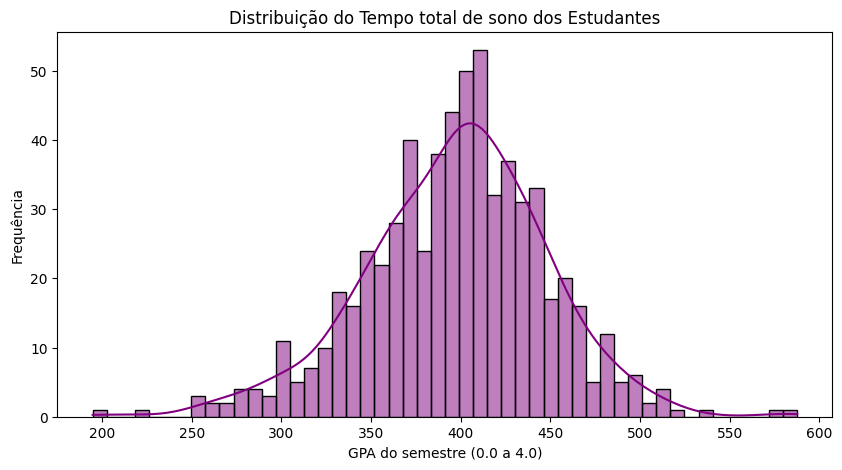

In [82]:
# b) Crie pelo menos um gráfico (histograma, boxplot) para visualizar a distribuição da variável escolhida.

# plotando um histograma da variavel 'term_gpa'
plt.figure(figsize=(10, 5))
sns.histplot(df['TotalSleepTime'], bins=50, kde=True, color='purple')
plt.title('Distribuição do Tempo total de sono dos Estudantes')
plt.xlabel('GPA do semestre (0.0 a 4.0)')
plt.ylabel('Frequência')
plt.show()

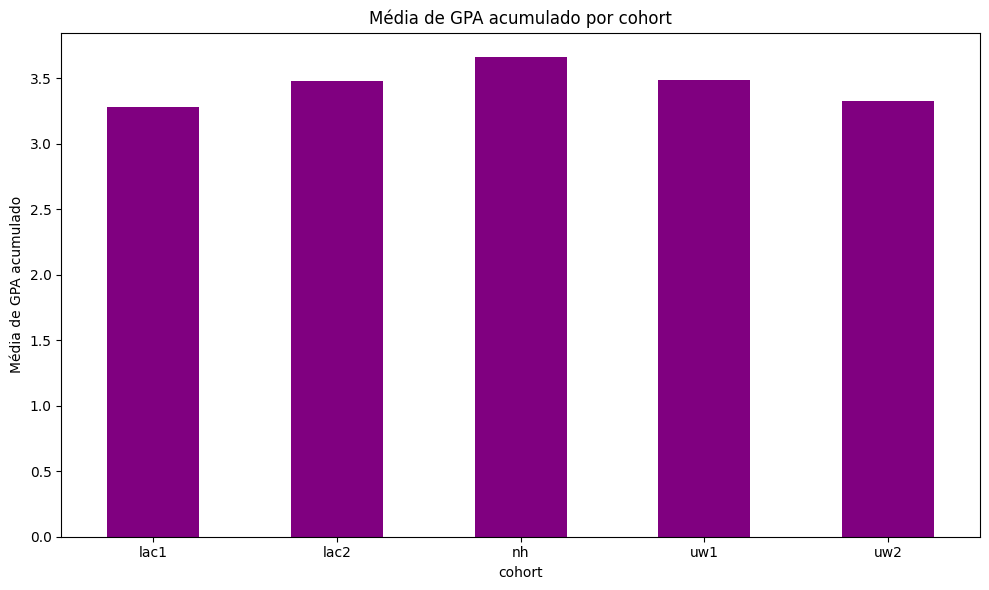

In [92]:
import matplotlib.pyplot as plt
import seaborn as sns

# agrupando por cohort
cohort_grp = df.groupby('cohort')

# agregar a média de do GPA cumulativo
mean_cum_gpa_per_cohort = cohort_grp['term_gpa'].agg('mean')

# visualização
plt.figure(figsize=(10, 6))
mean_cum_gpa_per_cohort.plot(kind='bar', title='Test', color='purple')
plt.title('Média de GPA acumulado por cohort')
plt.xlabel('cohort')
plt.ylabel('Média de GPA acumulado')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# o grupo nh teve o maior gpa acumulado

In [48]:
df['cohort'].value_counts()

,count
cohort,
nh,147
uw1,140
uw2,139
lac1,131
lac2,77


In [ ]:
# c) Interprete os resultados e discuta o que eles indicam sobre os padrões de sono dos indivíduos.

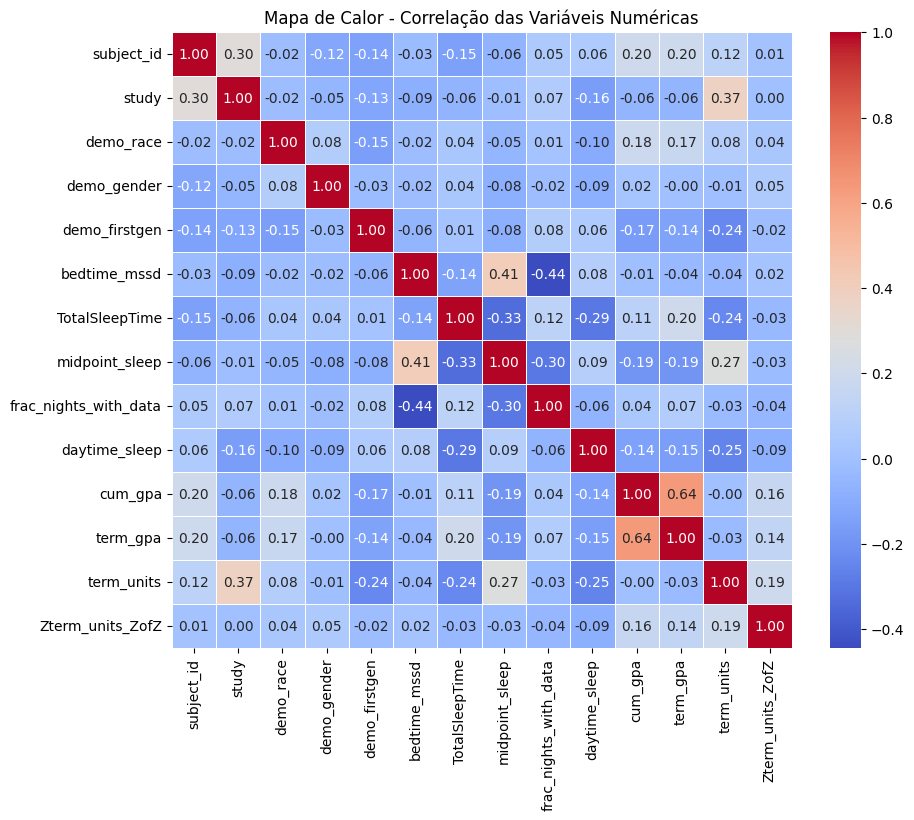

In [52]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

# 1. Seleciona apenas as colunas numéricas (int e float) e calcula a correlação
correlacao = df.select_dtypes(include=['number']).corr()

# 2. Plota o Heatmap
sns.heatmap(
    correlacao,
    annot=True,        # Mostra os números dentro dos quadrados
    cmap='coolwarm',   # Escala clássica: azul (negativo), branco (neutro), vermelho (positivo)
    fmt=".2f",         # Arredonda para 2 casas decimais
    linewidths=0.5
)

plt.title('Mapa de Calor - Correlação das Variáveis Numéricas')
plt.show()

# Questão 4: Comparação de Grupos (2 pontos)



Utilize a base de dados para comparar a qualidade do sono entre dois grupos (por exemplo, com base em idade, gênero ou condição de saúde).



a) Descreva a metodologia que você usaria para realizar essa comparação.



b) Quais insights você obteve sobre o sono dos indivíduos na base de dados?

As mulheres tiveram uma mediana de tempo de sono à noite maior, sonos durante dia menor que os homens. Por isso dá para dizer que a qualidade de sono das mulheres foi melhor que a dos homens.

As mulheres tem tambêm uma tendência a ter um desempenho escolar melhor do que os homens.



c) Como esses insights podem ser aplicados em contextos práticos, como intervenções de saúde ou desenvolvimento de tecnologias de monitoramento do sono?

Podemos medir o tempo de sono durante à noite, comparar com a sonolência de dia para perceber problemas como insônia.

A obtenção desses dados de sono podem ser utilizadas para alimentar um modelo preditor para prever tendências de padrões de sono baseadas em uma característica como gênero ou idade.

Esses insights podem ajudar a encontrar pessoas que enfrentam dificuldades no sono para ajudar a monitorar e a prescrever o medicamento correto e preciso para cada um.

In [83]:
# a) Descreva a metodologia que você usaria para realizar essa comparação.

male_filt = df['demo_gender'] == 0
fem_filt = df['demo_gender'] == 1


male_grp = df.loc[male_filt]
fem_grp = df.loc[fem_filt]

In [87]:
median_sleeptime_male = male_grp['TotalSleepTime'].median()
median_sleeptime_fem = fem_grp['TotalSleepTime'].median()

print(f"A mediana de tempo de sono para os homens foi {median_sleeptime_male}, e para as mulheres foi {median_sleeptime_fem}")

A mediana de tempo de sono para os homens foi 398.7894737, e para as mulheres foi 402.5962963


In [91]:
median_daytime_male = male_grp['daytime_sleep'].median()
median_daytime_fem = fem_grp['daytime_sleep'].median()

print(f"A mediana de tempo de sono/cochilo durante o dia para os homens foi {median_daytime_male}, e para as mulheres foi {median_daytime_fem}")

A mediana de tempo de sono/cochilo durante o dia para os homens foi 36.46428571, e para as mulheres foi 34.51787995


/tmp/ipykernel_5012/605604702.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='demo_gender', y='TotalSleepTime', palette='viridis')


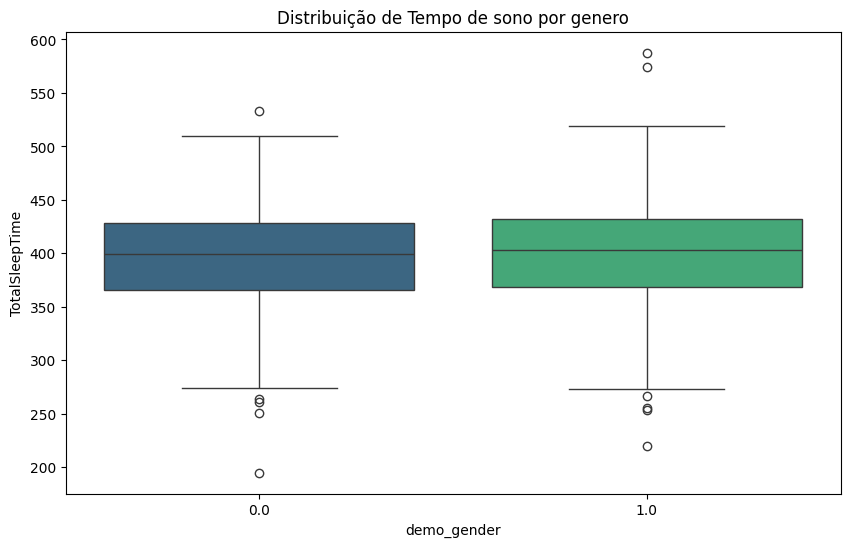

In [89]:
plt.figure(figsize=(10, 6))
# A ordem garante que o gráfico vá do pior para o melhor corte

sns.boxplot(data=df, x='demo_gender', y='TotalSleepTime', palette='viridis')
plt.title('Distribuição de Tempo de sono por genero')
plt.show()

In [76]:
df.head()

,subject_id,study,cohort,demo_race,demo_gender,demo_firstgen,bedtime_mssd,TotalSleepTime,midpoint_sleep,frac_nights_with_data,daytime_sleep,cum_gpa,term_gpa,term_units,Zterm_units_ZofZ
0,185,5,lac1,1.0,1.0,0.0,0.116727,432.200000,458.660000,0.862069,24.160000,3.00,3.38,73.0,4.055295
1,158,5,lac1,0.0,1.0,0.0,0.141681,391.931035,364.465517,1.000000,13.137931,3.66,2.60,64.0,2.482534
2,209,5,lac1,1.0,1.0,0.0,1.529289,344.304348,560.891304,0.793103,14.956522,3.57,3.07,63.0,2.307783
3,102,5,lac1,0.0,1.0,1.0,0.130148,392.620690,416.482759,1.000000,54.551724,3.61,3.56,61.0,1.958281
4,174,5,lac1,1.0,1.0,0.0,0.130181,423.421053,368.763158,0.655172,10.526316,3.21,4.00,61.0,1.958281
